# Diabetes Prediction — Exploratory Data Analysis

This notebook explores the diabetes prediction dataset before model training. The goal is to understand the dataset structure, check data quality, examine class imbalance, and look at how the model features relate to the target.

The EDA is intentionally kept separate from model training so that the final training pipeline can handle preprocessing consistently and without data leakage.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


# Make the notebook work whether it is opened from the
# project root or directly from the notebooks/ folder.
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "data").exists():
    PROJECT_ROOT = CURRENT_DIR
else:
    PROJECT_ROOT = CURRENT_DIR.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "diabetes_prediction_dataset.csv"
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")

Matplotlib is building the font cache; this may take a moment.


Project root: c:\diabetes_prediction_mlops
Dataset path: c:\diabetes_prediction_mlops\data\diabetes_prediction_dataset.csv


## 1. Load the Dataset

The dataset is restored through DVC and stored locally at `data/diabetes_prediction_dataset.csv`.

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 100,000
Columns: 9


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 2. Dataset Structure

The model uses eight input features and one binary target:

- `gender`
- `age`
- `hypertension`
- `heart_disease`
- `smoking_history`
- `bmi`
- `HbA1c_level`
- `blood_glucose_level`
- Target: `diabetes`

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [4]:
df.dtypes.to_frame("dtype")

,dtype
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


## 3. Data Quality Checks

Before analyzing distributions, I check for missing values and duplicate rows. Duplicate rows are removed before the modeling dataset is used.

In [5]:
quality_summary = pd.DataFrame(
    {
        "missing_values": df.isna().sum(),
        "missing_percent": (
            df.isna().mean() * 100
        ).round(2),
        "unique_values": df.nunique(),
    }
)

quality_summary

,missing_values,missing_percent,unique_values
gender,0,0.0,3
age,0,0.0,102
hypertension,0,0.0,2
heart_disease,0,0.0,2
smoking_history,0,0.0,6
bmi,0,0.0,4247
HbA1c_level,0,0.0,18
blood_glucose_level,0,0.0,18
diabetes,0,0.0,2


In [6]:
duplicate_count = int(
    df.duplicated().sum()
)

print(
    f"Duplicate rows: {duplicate_count:,}"
)

print(
    f"Duplicate percentage: "
    f"{duplicate_count / len(df) * 100:.2f}%"
)

Duplicate rows: 3,854
Duplicate percentage: 3.85%


In [7]:
clean_df = (
    df
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    f"Rows before duplicate removal: "
    f"{len(df):,}"
)

print(
    f"Rows after duplicate removal: "
    f"{len(clean_df):,}"
)

print(
    f"Rows removed: "
    f"{len(df) - len(clean_df):,}"
)

Rows before duplicate removal: 100,000
Rows after duplicate removal: 96,146
Rows removed: 3,854


## 4. Target Distribution

The `diabetes` column is the binary target. Because diabetes cases are less common than non-diabetes cases, accuracy alone would not be a strong enough evaluation metric.

This is why the modeling portion of the project also evaluates precision, recall, F1, F-beta, AUC-ROC, and Average Precision.

In [8]:
target_counts = (
    clean_df["diabetes"]
    .value_counts()
    .sort_index()
)

target_percent = (
    clean_df["diabetes"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

target_summary = pd.DataFrame(
    {
        "count": target_counts,
        "percent": target_percent.round(2),
    }
)

target_summary.index = [
    "No Diabetes (0)",
    "Diabetes (1)",
]

target_summary

,count,percent
No Diabetes (0),87664,91.18
Diabetes (1),8482,8.82


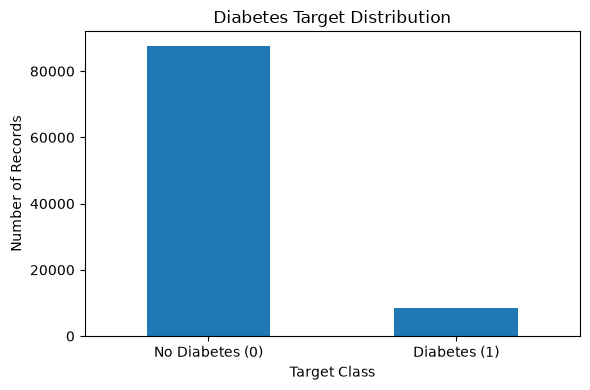

In [9]:
fig, ax = plt.subplots(
    figsize=(6, 4)
)

target_summary["count"].plot(
    kind="bar",
    ax=ax,
)

ax.set_title(
    "Diabetes Target Distribution"
)
ax.set_xlabel(
    "Target Class"
)
ax.set_ylabel(
    "Number of Records"
)
ax.tick_params(
    axis="x",
    rotation=0,
)

plt.tight_layout()
plt.show()

## 5. Numeric Feature Summary

The main continuous numeric features are age, BMI, HbA1c level, and blood glucose level.

In [10]:
numeric_features = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
]

clean_df[
    numeric_features
].describe().T

,count,mean,std,min,25%,50%,75%,max
age,96146.0,41.794326,22.462948,0.08,24.0,43.00,59.00,80.00
bmi,96146.0,27.321461,6.767716,10.01,23.4,27.32,29.86,95.69
HbA1c_level,96146.0,5.532609,1.073232,3.50,4.8,5.80,6.20,9.00
blood_glucose_level,96146.0,138.218231,40.909771,80.00,100.0,140.00,159.00,300.00


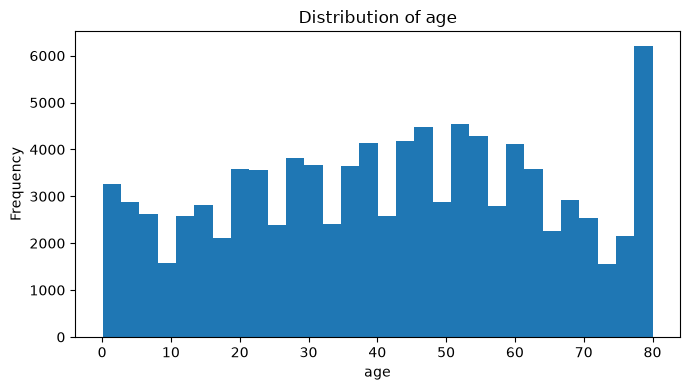

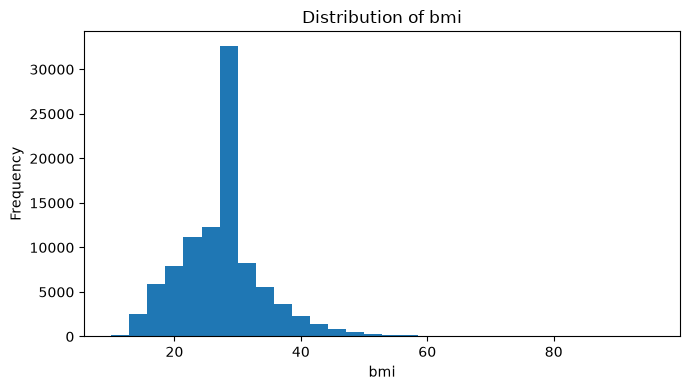

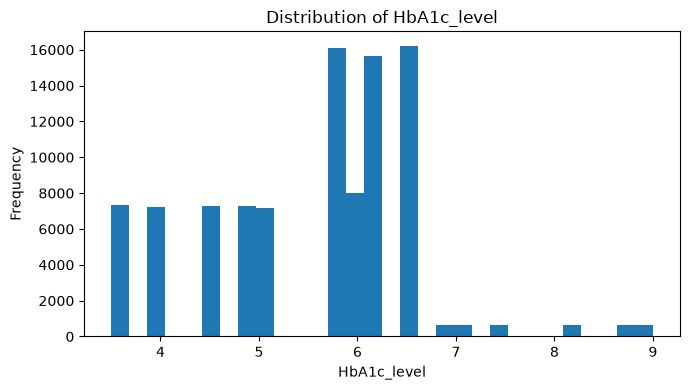

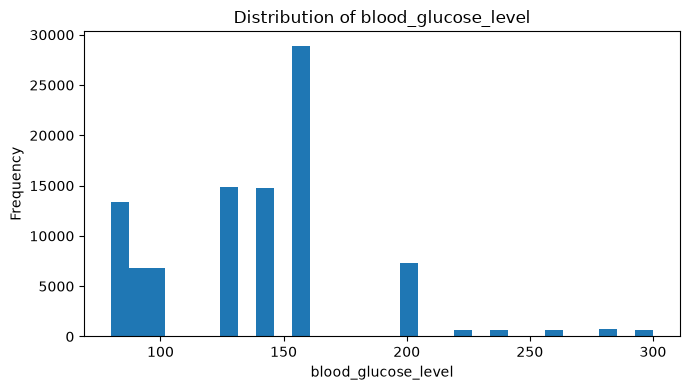

In [11]:
for feature in numeric_features:
    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    clean_df[feature].plot(
        kind="hist",
        bins=30,
        ax=ax,
    )

    ax.set_title(
        f"Distribution of {feature}"
    )
    ax.set_xlabel(
        feature
    )
    ax.set_ylabel(
        "Frequency"
    )

    plt.tight_layout()
    plt.show()

## 6. Numeric Features by Diabetes Status

These summaries compare each numeric feature between the two target classes. This does not establish medical causation; it only shows how the values are distributed in this dataset.

In [12]:
numeric_by_target = (
    clean_df
    .groupby("diabetes")[
        numeric_features
    ]
    .agg(
        ["mean", "median"]
    )
    .round(2)
)

numeric_by_target

age           bmi        HbA1c_level        blood_glucose_level  \
           mean median   mean median        mean median                mean   
diabetes                                                                      
0         39.94   40.0  26.87  27.32        5.40    5.8              132.82   
1         60.93   62.0  32.00  29.98        6.93    6.6              194.03   

                 
         median  
diabetes         
0         140.0  
1         160.0

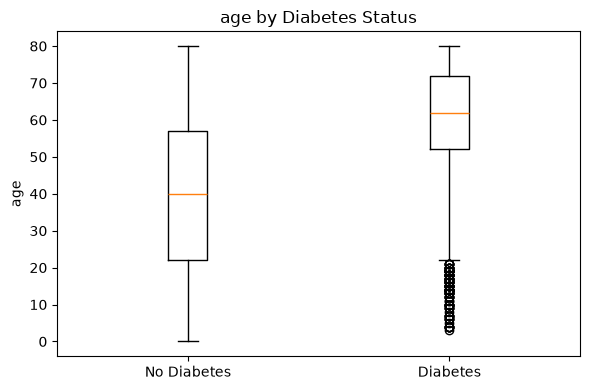

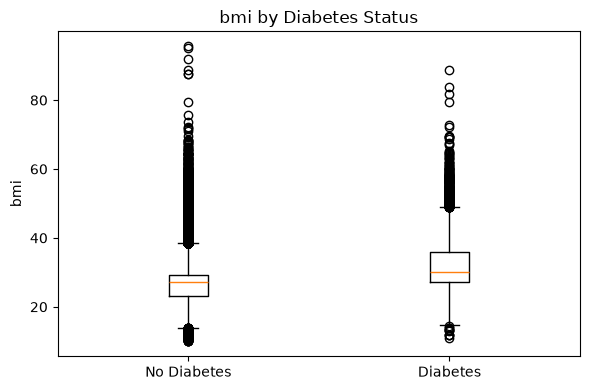

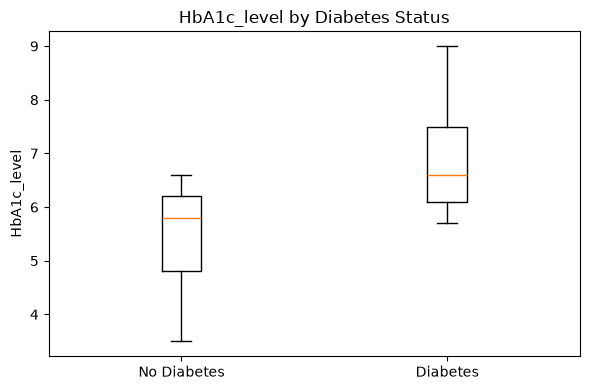

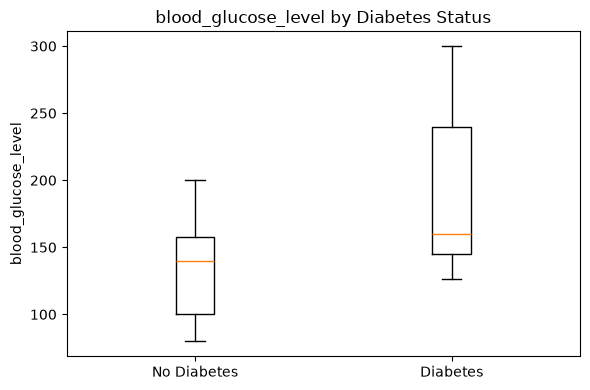

In [13]:
for feature in numeric_features:
    grouped = [
        clean_df.loc[
            clean_df["diabetes"] == target,
            feature,
        ]
        for target in [0, 1]
    ]

    fig, ax = plt.subplots(
        figsize=(6, 4)
    )

    ax.boxplot(
        grouped,
        tick_labels=[
            "No Diabetes",
            "Diabetes",
        ],
    )

    ax.set_title(
        f"{feature} by Diabetes Status"
    )
    ax.set_ylabel(
        feature
    )

    plt.tight_layout()
    plt.show()

## 7. Categorical Feature Distributions

The two categorical features are `gender` and `smoking_history`. These are one-hot encoded inside the training pipeline.

In [14]:
categorical_features = [
    "gender",
    "smoking_history",
]

for feature in categorical_features:
    summary = pd.DataFrame(
        {
            "count": (
                clean_df[feature]
                .value_counts()
            ),
            "percent": (
                clean_df[feature]
                .value_counts(
                    normalize=True
                )
                * 100
            ).round(2),
        }
    )

    print(
        f"\n{feature}"
    )

    display(summary)


gender


,count,percent
gender,,
Female,56161,58.41
Male,39967,41.57
Other,18,0.02



smoking_history


,count,percent
smoking_history,,
never,34398,35.78
No Info,32887,34.21
former,9299,9.67
current,9197,9.57
not current,6367,6.62
ever,3998,4.16


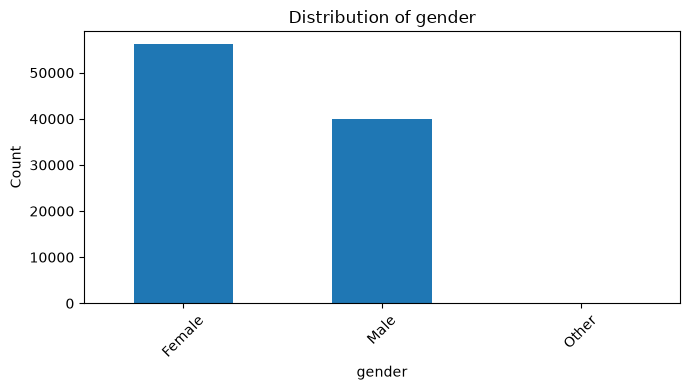

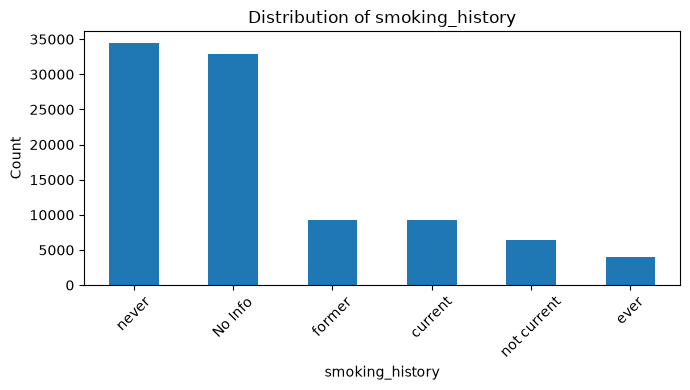

In [15]:
for feature in categorical_features:
    counts = (
        clean_df[feature]
        .value_counts()
    )

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    counts.plot(
        kind="bar",
        ax=ax,
    )

    ax.set_title(
        f"Distribution of {feature}"
    )
    ax.set_xlabel(
        feature
    )
    ax.set_ylabel(
        "Count"
    )
    ax.tick_params(
        axis="x",
        rotation=45,
    )

    plt.tight_layout()
    plt.show()

## 8. Binary Medical-History Features

`hypertension` and `heart_disease` are already represented as binary 0/1 features.

In [16]:
binary_features = [
    "hypertension",
    "heart_disease",
]

binary_summary = pd.DataFrame(
    {
        feature: {
            "No (0)": int(
                (clean_df[feature] == 0)
                .sum()
            ),
            "Yes (1)": int(
                (clean_df[feature] == 1)
                .sum()
            ),
            "Positive Rate (%)": round(
                clean_df[feature].mean()
                * 100,
                2,
            ),
        }
        for feature in binary_features
    }
).T

binary_summary

,No (0),Yes (1),Positive Rate (%)
hypertension,88685.0,7461.0,7.76
heart_disease,92223.0,3923.0,4.08


## 9. Diabetes Rate Across Categorical and Binary Features

The tables below make it easier to see whether the observed diabetes rate differs across categories in this dataset.

In [17]:
for feature in [
    "gender",
    "smoking_history",
    "hypertension",
    "heart_disease",
]:
    summary = (
        clean_df
        .groupby(feature)["diabetes"]
        .agg(
            records="count",
            diabetes_rate="mean",
        )
    )

    summary[
        "diabetes_rate"
    ] = (
        summary[
            "diabetes_rate"
        ]
        * 100
    ).round(2)

    print(
        f"\nDiabetes rate by {feature}"
    )

    display(summary)


Diabetes rate by gender


,records,diabetes_rate
gender,,
Female,56161,7.92
Male,39967,10.10
Other,18,0.00



Diabetes rate by smoking_history


,records,diabetes_rate
smoking_history,,
No Info,32887,4.39
current,9197,10.31
ever,3998,11.81
former,9299,17.10
never,34398,9.70
not current,6367,10.84



Diabetes rate by hypertension


,records,diabetes_rate
hypertension,,
0,88685,7.21
1,7461,27.96



Diabetes rate by heart_disease


,records,diabetes_rate
heart_disease,,
0,92223,7.82
1,3923,32.30


## 10. Correlation Between Numeric Features

Correlation is only a simple linear relationship measure, but it can still be useful for identifying features that move together.

Categorical features are not included in this matrix because they are encoded later in the model pipeline.

In [18]:
correlation_columns = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
    "hypertension",
    "heart_disease",
    "diabetes",
]

correlation_matrix = (
    clean_df[
        correlation_columns
    ]
    .corr()
    .round(2)
)

correlation_matrix

,age,bmi,HbA1c_level,blood_glucose_level,hypertension,heart_disease,diabetes
age,1.00,0.34,0.11,0.11,0.26,0.24,0.26
bmi,0.34,1.00,0.08,0.09,0.15,0.06,0.21
HbA1c_level,0.11,0.08,1.00,0.17,0.08,0.07,0.41
blood_glucose_level,0.11,0.09,0.17,1.00,0.08,0.07,0.42
hypertension,0.26,0.15,0.08,0.08,1.00,0.12,0.20
heart_disease,0.24,0.06,0.07,0.07,0.12,1.00,0.17
diabetes,0.26,0.21,0.41,0.42,0.20,0.17,1.00


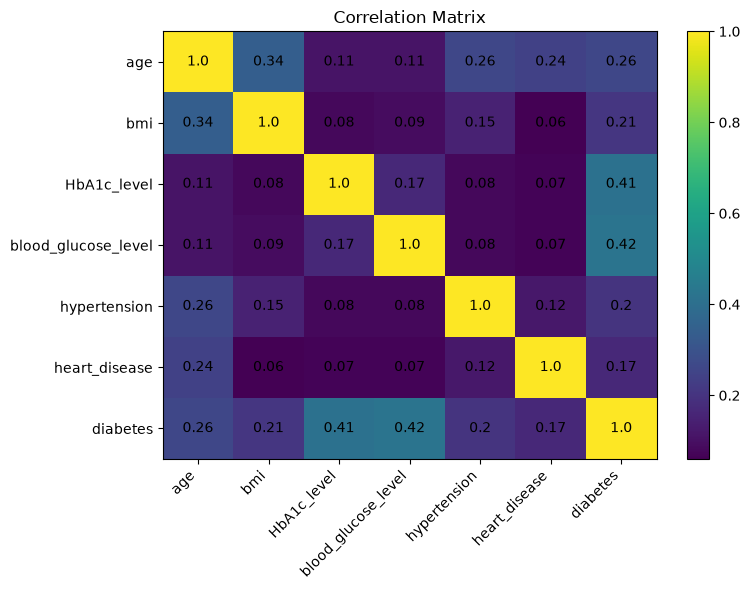

In [19]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

image = ax.imshow(
    correlation_matrix,
    aspect="auto",
)

ax.set_xticks(
    range(
        len(
            correlation_matrix.columns
        )
    )
)

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    range(
        len(
            correlation_matrix.index
        )
    )
)

ax.set_yticklabels(
    correlation_matrix.index
)

for row in range(
    len(
        correlation_matrix.index
    )
):
    for column in range(
        len(
            correlation_matrix.columns
        )
    ):
        ax.text(
            column,
            row,
            correlation_matrix.iloc[
                row,
                column,
            ],
            ha="center",
            va="center",
        )

ax.set_title(
    "Correlation Matrix"
)

fig.colorbar(
    image,
    ax=ax,
)

plt.tight_layout()
plt.show()

## 11. EDA Summary

The main findings from this exploration are:

- The raw dataset contains about 100,000 records.
- Duplicate observations are present, so duplicates are removed before model development.
- After duplicate removal, the modeling dataset contains roughly 96,000 unique observations.
- The diabetes target is imbalanced, with the positive class representing only a relatively small portion of the data.
- Because of that imbalance, model selection should not rely on accuracy alone.
- The project evaluates precision, recall, F1, F-beta, AUC-ROC, and Average Precision in addition to accuracy.
- Numeric features are scaled inside the Scikit-Learn pipeline.
- Categorical features are encoded inside the pipeline.
- Preprocessing is fitted only on the training data to help prevent data leakage.

This EDA is descriptive. Relationships shown here should not be interpreted as medical causation or clinical guidance.